# Stage 3 : Neural models: ResNet-18, EfficientNet-B2, ViT-Small + optimisation study

**Purpose:** train the three pretrained neural models **image-only and under the same conditions**, tune them with an
equal budget, run the ViT optimisation study , and produce learning curves and the validation comparison (Q3.a).

**Run on:** Colab with a **T4 GPU**

**Plan of runs (≈ 47 runs, same order of magnitude as the 64 classical configurations)**

| Phase | What | Runs |
|---|---|---|
| 1 | Initial ANN: ResNet-18 with default settings, 3 seeds | 3 |
| 2 | Equal tuning: the same 8 configurations (learning rate × weight decay × scene augmentation) for each model | 24 |
| 3 | ViT optimisation study: batch size, depth, optimiser (AdamW vs SGD), learning rate, freezing, class weights | 9 |
| 4 | Loss-region test (EDA Finding 02): zoomed centre view for the best ResNet-18 and ViT | 2 |
| 5 | Final models: best configuration of each model × 3 seeds | 9 |



## 0. Setup : platform, paths, GPU


In [ ]:
import os, sys, json, time, random, hashlib, zipfile, shutil, re, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42
FINAL_SEEDS = [42, 43, 44]
QUICK = os.environ.get("FN_QUICK") == "1"          # only used for offline testing — leave unset

IN_COLAB = "google.colab" in sys.modules
ON_KAGGLE = Path("/kaggle/working").exists()
if os.environ.get("FORESTNET_BASE"):
    BASE = Path(os.environ["FORESTNET_BASE"]); LOCAL = BASE / "local"
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/forestnet_project"); LOCAL = Path("/content/local")
elif ON_KAGGLE:
    BASE = Path("/kaggle/working/forestnet_project"); LOCAL = Path("/tmp/fn_local")
else:
    BASE = Path("./forestnet_project"); LOCAL = Path("./fn_local")

OUT3 = BASE / "outputs" / "stage3"; RUNS = OUT3 / "runs"; CACHE = BASE / "cache"
for d in (OUT3, RUNS, CACHE, LOCAL):
    d.mkdir(parents=True, exist_ok=True)
LOG_PATH = BASE / ("experiment_log_kaggle.csv" if ON_KAGGLE else "experiment_log.csv")

if ON_KAGGLE:   # copy the Stage 1 manifest + meta from the attached Kaggle dataset
    src = next(Path("/kaggle/input").rglob("split_manifest.csv")).parent
    (BASE / "outputs").mkdir(parents=True, exist_ok=True)
    for f in ("split_manifest.csv", "dataset_meta.json"):
        shutil.copy(src / f, BASE / "outputs" / f)
print("Project folder:", BASE, "| local fast disk:", LOCAL)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/forestnet_project | local fast disk: /content/local


In [ ]:
!pip -q install timm

import torch, torch.nn as nn, torch.nn.functional as F
import timm
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import f1_score, recall_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
pd.set_option("display.float_format", "{:.4g}".format)   # show small learning rates like 3e-05 properly
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

DEV = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEV == "cuda"
torch.backends.cudnn.benchmark = True
print("torch", torch.__version__, "| timm", timm.__version__, "| device:", DEV,
      torch.cuda.get_device_name(0) if DEV == "cuda" else "")
if DEV != "cuda" and not os.environ.get("FORESTNET_BASE"):
    print("WARNING: no GPU found — switch the runtime to T4 GPU before training.")

torch 2.11.0+cu130 | timm 1.0.30 | device: cuda Tesla T4


## 1. Frozen split (hash check), labels and metrics
The same checks and metric definitions as Stage 2, so the numbers are directly comparable.

In [ ]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

meta = json.load(open(BASE / "outputs" / "dataset_meta.json"))
assert sha256(BASE / "outputs" / "split_manifest.csv") == meta["manifest_sha256"], "Split changed!"
man = pd.read_csv(BASE / "outputs" / "split_manifest.csv").sort_values("example_path").reset_index(drop=True)
CLASSES = sorted(man["merged_label"].unique()); CLS2ID = {c: i for i, c in enumerate(CLASSES)}
man["y"] = man["merged_label"].map(CLS2ID)
P_ID, S_ID, O_ID, G_ID = (CLS2ID["Plantation"], CLS2ID["Smallholder agriculture"],
                          CLS2ID["Other"], CLS2ID["Grassland shrubland"])
TR_IDX = np.where(man.split == "train")[0]; VA_IDX = np.where(man.split == "val")[0]
print("Manifest OK | train", len(TR_IDX), "| val", len(VA_IDX), "| classes", CLS2ID)

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rec = recall_score(y_true, y_pred, labels=range(len(CLASSES)), average=None, zero_division=0)
    return {"macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred),
            "recall_plantation": rec[P_ID], "recall_other": rec[O_ID],
            "recall_smallholder": rec[S_ID], "recall_grassland": rec[G_ID],
            "rate_P_to_S": float((y_pred[y_true == P_ID] == S_ID).mean()),
            "rate_O_to_SG": float(np.isin(y_pred[y_true == O_ID], [S_ID, G_ID]).mean())}

Manifest OK | train 1616 | val 473 | classes {'Grassland shrubland': 0, 'Other': 1, 'Plantation': 2, 'Smallholder agriculture': 3}


## 2. Experiment log helpers


In [ ]:
LOG_COLS = ["run_id", "date", "stage", "model", "change", "hyperparameters", "seed",
            "val_macro_f1", "val_recall_plantation", "val_recall_other",
            "train_time_s", "infer_ms_per_img", "outcome", "note"]

def log_run(run_id, model, change, params, seed, m=None, train_s=None, infer_ms=None, outcome="ok", note=""):
    m = m or {}
    row = {"run_id": run_id, "date": time.strftime("%Y-%m-%d %H:%M"), "stage": "3", "model": model,
           "change": change, "hyperparameters": json.dumps(params, default=str), "seed": seed,
           "val_macro_f1": round(m.get("macro_f1", np.nan), 4),
           "val_recall_plantation": round(m.get("recall_plantation", np.nan), 4),
           "val_recall_other": round(m.get("recall_other", np.nan), 4),
           "train_time_s": None if train_s is None else round(train_s, 1),
           "infer_ms_per_img": None if infer_ms is None else round(infer_ms, 3),
           "outcome": outcome, "note": note}
    pd.DataFrame([row], columns=LOG_COLS).to_csv(LOG_PATH, mode="a", header=not LOG_PATH.exists(), index=False)

def add_lesson(run_id, text):
    log = pd.read_csv(LOG_PATH)
    hit = log.run_id == run_id
    assert hit.any(), f"{run_id} not in log"
    log.loc[hit, "note"] = log.loc[hit, "note"].fillna("").astype(str) + " | Lesson: " + text
    log.to_csv(LOG_PATH, index=False); print("Lesson added to", run_id)

## 3. Fast local image cache (built once, reused every session)
Reading thousands of small files from Drive took 55 minutes in Stage 2. Instead we:
1. extract **only the visible PNGs** from the zip onto the fast local disk,
2. resize each image once to **224 × 224** (the input size of all three pretrained models),
3. save everything as a few large arrays in Drive (`cache/`), which load in seconds next time.

Two **views** are stored: `full` (the whole 332-px image resized) and `zoom` (the central 166 px — about 2.5 km —
resized, so the loss area appears twice as large; used for the Finding 02 test).
**Single scenes:** only scenes whose file name says `cloud_0` are kept (EDA Finding 03: most scenes are cloudy).

In [ ]:
IMG = 224
ZOOM_BOX = (83, 83, 249, 249)                # centre 166 x 166 of the 332 x 332 image
CACHE_FILES = ["comp_full.npy", "comp_zoom.npy", "sc_full.npy", "sc_zoom.npy", "sc_start.npy", "sc_count.npy"]

def find_zip():
    z = BASE / "data" / "ForestNetDataset.zip"
    if z.exists():
        return z
    z = LOCAL / "ForestNetDataset.zip"
    if not z.exists():                       # Kaggle: download and verify against Stage 1 hash
        os.system(f"wget -q -O {z} {meta['dataset_url']}")
        assert sha256(z) == meta["zip_sha256"], "Downloaded zip differs from the Stage 1 file!"
    return z

RAW = None
def ensure_raw():
    """Extract only the visible PNGs to local disk (a few minutes, once per session)."""
    global RAW
    with zipfile.ZipFile(find_zip()) as zf:
        prefix = next(n for n in zf.namelist() if n.endswith("train.csv"))[:-len("train.csv")]
        RAW = LOCAL / "raw" / prefix
        if (RAW / "examples").exists():
            return RAW
        members = [n for n in zf.namelist() if n.startswith(prefix + "examples/") and "/images/visible/" in n]
        t0 = time.time(); zf.extractall(LOCAL / "raw", members)
        print(f"Extracted {len(members)} PNGs in {time.time() - t0:.0f}s")
    return RAW

def load_view(img, view):
    if view == "zoom":
        img = img.crop(ZOOM_BOX)
    return np.array(img.resize((IMG, IMG), Image.BILINEAR), dtype=np.uint8)

cache_meta_path = CACHE / "cache_meta.json"
cache_ok = cache_meta_path.exists() and all((CACHE / f).exists() for f in CACHE_FILES) and \
           json.load(open(cache_meta_path)).get("manifest_sha256") == meta["manifest_sha256"]
if cache_ok:
    t0 = time.time()
    arr = {f: np.load(CACHE / f) for f in CACHE_FILES}
    print(f"Loaded cache from Drive in {time.time() - t0:.0f}s")
else:
    raw = ensure_raw()
    comp_full, comp_zoom, sc_full, sc_zoom, sc_start, sc_count = [], [], [], [], [], []
    t0 = time.time()
    for p in man["example_path"]:
        vdir = raw / p / "images" / "visible"
        im = Image.open(vdir / "composite.png").convert("RGB")
        comp_full.append(load_view(im, "full")); comp_zoom.append(load_view(im, "zoom"))
        clear = sorted(f for f in vdir.glob("*.png") if re.search(r"cloud_0$", f.stem))
        sc_start.append(len(sc_full)); sc_count.append(len(clear))
        for f in clear:
            s = Image.open(f).convert("RGB")
            sc_full.append(load_view(s, "full")); sc_zoom.append(load_view(s, "zoom"))
    empty = np.zeros((0, IMG, IMG, 3), np.uint8)
    arr = {"comp_full.npy": np.stack(comp_full), "comp_zoom.npy": np.stack(comp_zoom),
           "sc_full.npy": np.stack(sc_full) if sc_full else empty, "sc_zoom.npy": np.stack(sc_zoom) if sc_zoom else empty,
           "sc_start.npy": np.array(sc_start), "sc_count.npy": np.array(sc_count)}
    print(f"Built cache in {time.time() - t0:.0f}s")
    for f, a in arr.items():
        np.save(CACHE / f, a)
    json.dump({"manifest_sha256": meta["manifest_sha256"], "img": IMG, "zoom_box": ZOOM_BOX,
               "scene_rule": "cloud_0 only", "created": time.strftime("%Y-%m-%d %H:%M")}, open(cache_meta_path, "w"))

print("Composites:", arr["comp_full.npy"].shape, "| clear single scenes:", arr["sc_full.npy"].shape[0],
      "| train events with ≥1 clear scene:", int((arr["sc_count.npy"][TR_IDX] > 0).sum()), "of", len(TR_IDX))

Extracted 12860 PNGs in 63s
Built cache in 49s
Composites: (2757, 224, 224, 3) | clear single scenes: 2877 | train events with ≥1 clear scene: 820 of 1616


## 4. Putting the data on the GPU, normalisation and augmentation
- The whole cache (uint8, about 1.5 GB) is moved to GPU memory once; batches are then cut out instantly.
- **Normalisation:** each channel is standardised with the **training-set** mean and std saved in Stage 1
  (the composites are much darker than ImageNet photos, so ImageNet statistics would be a poor fit).
- **Augmentation (training only):** random horizontal flip, vertical flip and 90° rotation : satellite images have no
  "up", so these do not change the meaning of the image. With **scene augmentation**, half of the time a training
  event is shown as one of its cloud-free single scenes instead of its composite (more views of the same place).
- Validation always uses the composite, without augmentation.

In [ ]:
MEAN = torch.tensor(meta["train_rgb_norm"]["mean"], device=DEV).view(1, 3, 1, 1)
STD = torch.tensor(meta["train_rgb_norm"]["std"], device=DEV).view(1, 3, 1, 1)
Y = torch.tensor(man["y"].values, device=DEV)
GPU = {}
def to_gpu(view):
    if view not in GPU:
        GPU.clear(); torch.cuda.empty_cache() if DEV == "cuda" else None
        GPU[view] = (torch.from_numpy(arr[f"comp_{view}.npy"]).to(DEV), torch.from_numpy(arr[f"sc_{view}.npy"]).to(DEV))
    return GPU[view]
SC_START = torch.tensor(arr["sc_start.npy"], device=DEV); SC_COUNT = torch.tensor(arr["sc_count.npy"], device=DEV)

def make_batch(idx, view, train=False, scenes="none", p_scene=0.5):
    comp, sc = to_gpu(view)
    x = comp[idx]
    if train and scenes == "clear" and sc.shape[0] > 0:
        use = (SC_COUNT[idx] > 0) & (torch.rand(len(idx), device=DEV) < p_scene)
        if use.any():
            j = SC_START[idx[use]] + (torch.rand(int(use.sum()), device=DEV) * SC_COUNT[idx[use]]).long()
            x = x.clone(); x[use] = sc[j]
    x = (x.permute(0, 3, 1, 2).float() / 255.0 - MEAN) / STD
    if train:
        B = x.shape[0]
        x = torch.where((torch.rand(B, device=DEV) < 0.5).view(B, 1, 1, 1), x.flip(3), x)
        x = torch.where((torch.rand(B, device=DEV) < 0.5).view(B, 1, 1, 1), x.flip(2), x)
        k = torch.randint(0, 4, (B,), device=DEV); out = x.clone()
        for r in (1, 2, 3):
            m = k == r
            if m.any():
                out[m] = torch.rot90(x[m], r, dims=(2, 3))
        x = out
    return x

## 5. The three architectures
All start from **ImageNet-pretrained** weights (timm library) and receive the same 224 × 224 RGB input.

| Model | timm weights | Head | Fine-tuning |
|---|---|---|---|
| ResNet-18 (initial ANN) | `resnet18.tv_in1k` | standard linear layer → 4 classes | all layers |
| EfficientNet-B2 (ForestNet's backbone) | `efficientnet_b2.ra_in1k` | standard linear layer → 4 classes | all layers |
| ViT-Small/16 (final ANN) | `vit_small_patch16_224.augreg_in21k_ft_in1k` | **own head** (below) | patch embedding + first `n_frozen` blocks frozen |

**Own ViT head:** the [CLS] token (global summary) is concatenated with the **mean of the 196 patch tokens**
(average local evidence) → LayerNorm → Dropout → Linear(768→256) → GELU → Dropout → Linear(256→4).
**Depth** : the ViT keeps only its first `depth` transformer blocks (6, 9 or 12).
**Freezing:** early blocks learn generic edges/colours; freezing them reduces overfitting on 1,616 training images.

In [ ]:
TIMM_NAMES = {"resnet18": "resnet18.tv_in1k", "effnet_b2": "efficientnet_b2.ra_in1k",
              "vit_small": "vit_small_patch16_224.augreg_in21k_ft_in1k"}
PRETRAINED = os.environ.get("FN_PRETRAINED", "1") == "1"

class ViTClassifier(nn.Module):
    def __init__(self, depth=12, n_frozen=3, hidden=256, drop=0.2):
        super().__init__()
        self.backbone = timm.create_model(TIMM_NAMES["vit_small"], pretrained=PRETRAINED, num_classes=0)
        self.backbone.blocks = self.backbone.blocks[:depth]
        d = self.backbone.num_features
        self.head = nn.Sequential(nn.LayerNorm(2 * d), nn.Dropout(drop), nn.Linear(2 * d, hidden),
                                  nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, len(CLASSES)))
        frozen = [self.backbone.patch_embed, *self.backbone.blocks[:n_frozen]]
        for mod in frozen:
            for p in mod.parameters():
                p.requires_grad = False
        self.backbone.cls_token.requires_grad = False
        self.backbone.pos_embed.requires_grad = False

    def forward(self, x):
        t = self.backbone.forward_features(x)                 # (B, 1 + 196, 384) after final LayerNorm
        return self.head(torch.cat([t[:, 0], t[:, 1:].mean(1)], dim=1))

def build_model(cfg):
    if cfg["arch"] == "vit_small":
        return ViTClassifier(cfg["depth"], cfg["n_frozen"], cfg["hidden"], cfg["drop"])
    return timm.create_model(TIMM_NAMES[cfg["arch"]], pretrained=PRETRAINED, num_classes=len(CLASSES))

def count_params(model):
    tot = sum(p.numel() for p in model.parameters()); tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, tr

## 6. Training one run
- **Loss:** cross-entropy with **class weights** (inverse class frequency on train) : EDA Finding 01.
- **Optimiser:** AdamW (default) or SGD with Nesterov momentum 0.9 (optimiser comparison).
- **Schedule:** 1 warm-up epoch, then cosine decay; at most `MAX_EPOCHS`;                                                                                                                              **early stopping** after `PATIENCE`
  epochs without improvement in validation macro-F1; the weights from the **best epoch** are kept.
- **Mixed precision** (float16) roughly doubles speed on a T4; gradients are clipped at 1.0 for stability.
- Each epoch records train loss, train macro-F1 (on un-augmented composites) and validation loss / macro-F1 →
  learning curves for under/overfitting analysis.
- A run whose loss becomes NaN is stopped and logged as **failed (diverged)**.

In [ ]:
MAX_EPOCHS = 2 if QUICK else 30
PATIENCE = 7
WARMUP_EPOCHS = 1
counts = np.bincount(man["y"].values[TR_IDX], minlength=len(CLASSES))
CLASS_W = torch.tensor(len(TR_IDX) / (len(CLASSES) * counts), dtype=torch.float32, device=DEV)
print("Class weights:", dict(zip(CLASSES, CLASS_W.cpu().numpy().round(3))))

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict(model, idx_np, view, bs=128, crit=None):
    model.eval(); preds, losses = [], []
    idx_all = torch.tensor(idx_np, device=DEV)
    for b in range(0, len(idx_all), bs):
        idx = idx_all[b:b + bs]
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
            out = model(make_batch(idx, view)).float()
        preds.append(out.argmax(1).cpu())
        if crit is not None:
            losses.append(crit(out, Y[idx]).item() * len(idx))
    return torch.cat(preds).numpy(), (sum(losses) / len(idx_all) if crit is not None else None)

def make_optimizer(cfg, model):
    params = [p for p in model.parameters() if p.requires_grad]
    if cfg["opt"] == "sgd":
        return torch.optim.SGD(params, lr=cfg["lr"], momentum=0.9, nesterov=True, weight_decay=cfg["wd"])
    return torch.optim.AdamW(params, lr=cfg["lr"], weight_decay=cfg["wd"])

def run_experiment(cfg):
    rid = cfg["run_id"]; rdir = RUNS / rid
    if (rdir / "result.json").exists():
        res = json.load(open(rdir / "result.json")); print(f"{rid}: already done (val macro-F1 {res['val']['macro_f1']:.4f}) — skipped")
        return res
    rdir.mkdir(parents=True, exist_ok=True); set_seed(cfg["seed"])
    model = build_model(cfg).to(DEV)
    n_tot, n_tr = count_params(model)
    opt = make_optimizer(cfg, model)
    steps = math.ceil(len(TR_IDX) / cfg["bs"]); total = steps * MAX_EPOCHS; warm = steps * WARMUP_EPOCHS
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    crit = nn.CrossEntropyLoss(weight=CLASS_W if cfg["class_weights"] else None)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    tr_idx_t = torch.tensor(TR_IDX, device=DEV)
    hist, best_f1, best_ep, best_state, bad, outcome = [], -1.0, 0, None, 0, "ok"
    t0 = time.time()
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); run_loss, nan = 0.0, False
        perm = tr_idx_t[torch.randperm(len(tr_idx_t), device=DEV)]
        for b in range(steps):
            idx = perm[b * cfg["bs"]:(b + 1) * cfg["bs"]]
            x = make_batch(idx, cfg["view"], train=True, scenes=cfg["scenes"])
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                loss = crit(model(x).float(), Y[idx])
            if not torch.isfinite(loss):
                nan = True; break
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run_loss += loss.item() * len(idx)
        if nan:
            outcome = "failed (diverged: NaN loss)"; break
        tr_pred, tr_loss_eval = predict(model, TR_IDX, cfg["view"], crit=crit)
        va_pred, va_loss = predict(model, VA_IDX, cfg["view"], crit=crit)
        tr_f1 = f1_score(man.y.values[TR_IDX], tr_pred, average="macro")
        va_f1 = f1_score(man.y.values[VA_IDX], va_pred, average="macro")
        hist.append({"epoch": ep, "train_loss_aug": run_loss / len(TR_IDX), "train_loss": tr_loss_eval,
                     "train_macro_f1": tr_f1, "val_loss": va_loss, "val_macro_f1": va_f1,
                     "lr": opt.param_groups[0]["lr"], "time_s": time.time() - t0})
        if va_f1 > best_f1:
            best_f1, best_ep, bad = va_f1, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if bad >= PATIENCE:
            break
    train_s = time.time() - t0
    pd.DataFrame(hist).to_csv(rdir / "history.csv", index=False)
    params = {k: v for k, v in cfg.items() if k not in ("run_id", "change", "save")}
    if best_state is None:
        log_run(rid, cfg["arch"], cfg["change"], params, cfg["seed"], train_s=train_s, outcome=outcome,
                note=f"stopped at epoch {len(hist) + 1}")
        res = {"cfg": cfg, "val": {"macro_f1": float("nan")}, "outcome": outcome, "train_s": train_s, "history": hist}
        json.dump(res, open(rdir / "result.json", "w"), indent=2, default=str)
        print(f"{rid}: {outcome}"); return res
    model.load_state_dict(best_state)
    va_pred, _ = predict(model, VA_IDX, cfg["view"])
    m = evaluate(man.y.values[VA_IDX], va_pred)
    note = f"best epoch {best_ep}/{len(hist)}; params {n_tot/1e6:.1f}M total, {n_tr/1e6:.1f}M trainable"
    log_run(rid, cfg["arch"], cfg["change"], params, cfg["seed"], m, train_s, outcome=outcome, note=note)
    res = {"cfg": cfg, "val": m, "best_epoch": best_ep, "epochs_run": len(hist), "train_s": train_s,
           "params_total": n_tot, "params_trainable": n_tr, "outcome": outcome}
    json.dump(res, open(rdir / "result.json", "w"), indent=2, default=str)
    np.save(rdir / "val_pred.npy", va_pred)
    if cfg.get("save"):
        torch.save(best_state, rdir / "best.pt")
    print(f"{rid}: val macro-F1 {m['macro_f1']:.4f} | best epoch {best_ep}/{len(hist)} | {train_s/60:.1f} min")
    del model, opt; torch.cuda.empty_cache() if DEV == "cuda" else None
    return res

def run_all(cfgs):
    out = []
    for c in cfgs:
        try:
            out.append(run_experiment(c))
        except Exception as e:                       # e.g. out of memory: logged as a failed attempt
            log_run(c["run_id"], c["arch"], c["change"], {k: v for k, v in c.items() if k not in ("run_id", "change")},
                    c["seed"], outcome="failed (error)", note=repr(e)[:200])
            print(f"{c['run_id']}: FAILED {e!r}"); torch.cuda.empty_cache() if DEV == "cuda" else None
    return out

def results_table(prefix=""):
    rows = []
    for f in sorted(RUNS.glob("*/result.json")):
        r = json.load(open(f))
        if not r["cfg"]["run_id"].startswith(prefix):
            continue
        rows.append({"run_id": r["cfg"]["run_id"], "arch": r["cfg"]["arch"], **{k: r["cfg"][k] for k in
                     ("lr", "wd", "bs", "opt", "scenes", "view", "depth", "n_frozen", "class_weights", "seed")},
                     "val_macro_f1": r["val"]["macro_f1"], "best_epoch": r.get("best_epoch"),
                     "train_min": r["train_s"] / 60, "outcome": r["outcome"]})
    return pd.DataFrame(rows)

Class weights: {'Grassland shrubland': np.float32(2.825), 'Other': np.float32(1.749), 'Plantation': np.float32(0.589), 'Smallholder agriculture': np.float32(0.727)}


## 7. Default settings shared by every run
Anything not changed by a specific experiment uses these values.

In [ ]:
DEFAULT = dict(seed=SEED, view="full", scenes="none", bs=64, opt="adamw", wd=0.05, class_weights=True,
               depth=12, n_frozen=3, hidden=256, drop=0.2, save=False)

def cfg(run_id, arch, change, **kw):
    return {**DEFAULT, "run_id": run_id, "arch": arch, "change": change, **kw}

## Phase 1 : Initial ANN: ResNet-18 with default settings (3 seeds)
AdamW, learning rate 3e-4, weight decay 0.05, batch 64, composite only. **Note the time per run** printed below -
paste it to me if runs take much longer than ~5 minutes, so the budget can be adjusted.

In [ ]:
P1 = [cfg(f"S3-R18-INIT-s{s}", "resnet18", "initial ANN: ResNet-18 default settings", lr=3e-4, seed=s, save=True)
      for s in FINAL_SEEDS]
run_all(P1)
display(results_table("S3-R18-INIT"))

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

S3-R18-INIT-s42: val macro-F1 0.7484 | best epoch 18/25 | 1.1 min
S3-R18-INIT-s43: val macro-F1 0.7440 | best epoch 15/22 | 1.1 min
S3-R18-INIT-s44: val macro-F1 0.7039 | best epoch 3/10 | 0.5 min


,run_id,arch,lr,wd,bs,opt,scenes,view,depth,n_frozen,class_weights,seed,val_macro_f1,best_epoch,train_min,outcome
0,S3-R18-INIT-s42,resnet18,0.0003,0.05,64,adamw,none,full,12,3,True,42,0.7484,18,1.139,ok
1,S3-R18-INIT-s43,resnet18,0.0003,0.05,64,adamw,none,full,12,3,True,43,0.744,15,1.078,ok
2,S3-R18-INIT-s44,resnet18,0.0003,0.05,64,adamw,none,full,12,3,True,44,0.7039,3,0.4763,ok


## Phase 2 : Equal tuning budget: the same 8 configurations for every model
Search space (12 combinations), of which the **same 8** (drawn once with seed 42) are run for each model:
- learning rate: 3 values per model family (CNNs fine-tune well at higher rates than ViTs);
- weight decay: 0.01 or 0.05;
- scene augmentation: none, or cloud-free single scenes (EDA Finding 03).

In [ ]:
LR_SETS = {"resnet18": [1e-4, 3e-4, 1e-3], "effnet_b2": [1e-4, 3e-4, 1e-3], "vit_small": [3e-5, 1e-4, 3e-4]}
COMBOS = [(li, wd, sc) for li in range(3) for wd in (0.01, 0.05) for sc in ("none", "clear")]
CHOSEN = sorted(np.random.default_rng(SEED).choice(len(COMBOS), size=1 if QUICK else 8, replace=False).tolist())
SHORT = {"resnet18": "R18", "effnet_b2": "EFB2", "vit_small": "VIT"}
P2 = [cfg(f"S3-{SHORT[a]}-T{k + 1:02d}", a, "tuning (equal budget)",
          lr=LR_SETS[a][COMBOS[c][0]], wd=COMBOS[c][1], scenes=COMBOS[c][2])
      for a in ("resnet18", "effnet_b2", "vit_small") for k, c in enumerate(CHOSEN)]
print(len(P2), "runs:", [(COMBOS[c]) for c in CHOSEN])

24 runs: [(0, 0.01, 'none'), (0, 0.05, 'clear'), (1, 0.01, 'none'), (1, 0.05, 'none'), (2, 0.01, 'none'), (2, 0.01, 'clear'), (2, 0.05, 'none'), (2, 0.05, 'clear')]


In [ ]:
run_all([c for c in P2 if c["arch"] == "resnet18"])

S3-R18-T01: val macro-F1 0.7350 | best epoch 11/18 | 0.9 min
S3-R18-T02: val macro-F1 0.7536 | best epoch 10/17 | 0.8 min
S3-R18-T03: val macro-F1 0.7766 | best epoch 24/30 | 1.5 min
S3-R18-T04: val macro-F1 0.7484 | best epoch 18/25 | 1.2 min
S3-R18-T05: val macro-F1 0.7374 | best epoch 15/22 | 1.1 min
S3-R18-T06: val macro-F1 0.7520 | best epoch 23/30 | 1.5 min
S3-R18-T07: val macro-F1 0.7478 | best epoch 21/28 | 1.4 min
S3-R18-T08: val macro-F1 0.7273 | best epoch 11/18 | 0.9 min


[{'cfg': {'seed': 42,
   'view': 'full',
   'scenes': 'none',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.01,
   'class_weights': True,
   'depth': 12,
   'n_frozen': 3,
   'hidden': 256,
   'drop': 0.2,
   'save': False,
   'run_id': 'S3-R18-T01',
   'arch': 'resnet18',
   'change': 'tuning (equal budget)',
   'lr': 0.0001},
  'val': {'macro_f1': 0.7349738593952103,
   'accuracy': 0.7885835095137421,
   'recall_plantation': np.float64(0.8669724770642202),
   'recall_other': np.float64(0.7428571428571429),
   'recall_smallholder': np.float64(0.7785714285714286),
   'recall_grassland': np.float64(0.5111111111111111),
   'rate_P_to_S': 0.0779816513761468,
   'rate_O_to_SG': 0.2},
  'best_epoch': 11,
  'epochs_run': 18,
  'train_s': 54.377782344818115,
  'params_total': 11178564,
  'params_trainable': 11178564,
  'outcome': 'ok'},
 {'cfg': {'seed': 42,
   'view': 'full',
   'scenes': 'clear',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.05,
   'class_weights': True,
   'depth': 12,
   'n_fro

In [ ]:
run_all([c for c in P2 if c["arch"] == "effnet_b2"])

model.safetensors: reconstructing file:   0%|          |  0.00B / 36.8MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_577/3766558193.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


S3-EFB2-T01: val macro-F1 0.6984 | best epoch 20/27 | 4.7 min


/tmp/ipykernel_577/3766558193.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


S3-EFB2-T02: val macro-F1 0.7060 | best epoch 28/30 | 4.1 min


... (9 outputs left out)

S3-EFB2-T07: val macro-F1 0.7410 | best epoch 26/30 | 4.2 min


/tmp/ipykernel_577/3766558193.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


S3-EFB2-T08: val macro-F1 0.7408 | best epoch 14/21 | 2.9 min


[{'cfg': {'seed': 42,
   'view': 'full',
   'scenes': 'none',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.01,
   'class_weights': True,
   'depth': 12,
   'n_frozen': 3,
   'hidden': 256,
   'drop': 0.2,
   'save': False,
   'run_id': 'S3-EFB2-T01',
   'arch': 'effnet_b2',
   'change': 'tuning (equal budget)',
   'lr': 0.0001},
  'val': {'macro_f1': 0.6984025704142431,
   'accuracy': 0.7547568710359408,
   'recall_plantation': np.float64(0.8577981651376146),
   'recall_other': np.float64(0.6142857142857143),
   'recall_smallholder': np.float64(0.7071428571428572),
   'recall_grassland': np.float64(0.6222222222222222),
   'rate_P_to_S': 0.08256880733944955,
   'rate_O_to_SG': 0.3142857142857143},
  'best_epoch': 20,
  'epochs_run': 27,
  'train_s': 283.5275318622589,
  'params_total': 7706630,
  'params_trainable': 7706630,
  'outcome': 'ok'},
 {'cfg': {'seed': 42,
   'view': 'full',
   'scenes': 'clear',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.05,
   'class_weights': True,
   'depth'

In [ ]:
run_all([c for c in P2 if c["arch"] == "vit_small"])

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

S3-VIT-T01: val macro-F1 0.7607 | best epoch 11/18 | 2.1 min
S3-VIT-T02: val macro-F1 0.7648 | best epoch 22/29 | 3.3 min
S3-VIT-T03: val macro-F1 0.7634 | best epoch 22/29 | 3.3 min
S3-VIT-T04: val macro-F1 0.7585 | best epoch 15/22 | 2.5 min
S3-VIT-T05: val macro-F1 0.7398 | best epoch 23/30 | 3.4 min
S3-VIT-T06: val macro-F1 0.7719 | best epoch 8/15 | 1.7 min
S3-VIT-T07: val macro-F1 0.7473 | best epoch 7/14 | 1.6 min
S3-VIT-T08: val macro-F1 0.7423 | best epoch 5/12 | 1.4 min


[{'cfg': {'seed': 42,
   'view': 'full',
   'scenes': 'none',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.01,
   'class_weights': True,
   'depth': 12,
   'n_frozen': 3,
   'hidden': 256,
   'drop': 0.2,
   'save': False,
   'run_id': 'S3-VIT-T01',
   'arch': 'vit_small',
   'change': 'tuning (equal budget)',
   'lr': 3e-05},
  'val': {'macro_f1': 0.7607296016503509,
   'accuracy': 0.7906976744186046,
   'recall_plantation': np.float64(0.8394495412844036),
   'recall_other': np.float64(0.7142857142857143),
   'recall_smallholder': np.float64(0.8),
   'recall_grassland': np.float64(0.6444444444444445),
   'rate_P_to_S': 0.10550458715596331,
   'rate_O_to_SG': 0.15714285714285714},
  'best_epoch': 11,
  'epochs_run': 18,
  'train_s': 127.44790625572205,
  'params_total': 21865092,
  'params_trainable': 16170372,
  'outcome': 'ok'},
 {'cfg': {'seed': 42,
   'view': 'full',
   'scenes': 'clear',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.05,
   'class_weights': True,
   'depth': 12,
   'n_f

In [ ]:
t2 = results_table("S3-").query("run_id.str.contains('-T')", engine="python")
display(t2.sort_values(["arch", "val_macro_f1"], ascending=[True, False]))

def best_cfg(arch, extra_prefixes=("-T",)):
    t = results_table("S3-")
    t = t[(t.arch == arch) & t.run_id.apply(lambda r: any(p in r for p in extra_prefixes))].dropna(subset=["val_macro_f1"])
    rid = t.sort_values("val_macro_f1", ascending=False).iloc[0]["run_id"]
    return json.load(open(RUNS / rid / "result.json"))["cfg"]

for a in SHORT:
    b = best_cfg(a); print(a, "best tuning run:", b["run_id"], {k: b[k] for k in ("lr", "wd", "scenes")})

,run_id,arch,lr,wd,bs,opt,scenes,view,depth,n_frozen,class_weights,seed,val_macro_f1,best_epoch,train_min,outcome
4,S3-EFB2-T05,effnet_b2,0.001,0.01,64,adamw,none,full,12,3,True,42,0.7586,26,4.127,ok
5,S3-EFB2-T06,effnet_b2,0.001,0.01,64,adamw,clear,full,12,3,True,42,0.7523,9,2.228,ok
2,S3-EFB2-T03,effnet_b2,0.0003,0.01,64,adamw,none,full,12,3,True,42,0.7477,22,3.959,ok
6,S3-EFB2-T07,effnet_b2,0.001,0.05,64,adamw,none,full,12,3,True,42,0.741,26,4.154,ok
7,S3-EFB2-T08,effnet_b2,0.001,0.05,64,adamw,clear,full,12,3,True,42,0.7408,14,2.896,ok
3,S3-EFB2-T04,effnet_b2,0.0003,0.05,64,adamw,none,full,12,3,True,42,0.7338,20,3.694,ok
1,S3-EFB2-T02,effnet_b2,0.0001,0.05,64,adamw,clear,full,12,3,True,42,0.706,28,4.146,ok
0,S3-EFB2-T01,effnet_b2,0.0001,0.01,64,adamw,none,full,12,3,True,42,0.6984,20,4.725,ok
13,S3-R18-T03,resnet18,0.0003,0.01,64,adamw,none,full,12,3,True,42,0.7766,24,1.454,ok
12,S3-R18-T02,resnet18,0.0001,0.05,64,adamw,clear,full,12,3,True,42,0.7536,10,0.8147,ok


resnet18 best tuning run: S3-R18-T03 {'lr': 0.0003, 'wd': 0.01, 'scenes': 'none'}
effnet_b2 best tuning run: S3-EFB2-T05 {'lr': 0.001, 'wd': 0.01, 'scenes': 'none'}
vit_small best tuning run: S3-VIT-T06 {'lr': 0.0003, 'wd': 0.01, 'scenes': 'clear'}


## Phase 3 : ViT optimisation study
Starting from the best ViT tuning configuration, **one factor is changed at a time**, so any change in results can be
attributed to that factor:

| Study | Values compared | Brief link |
|---|---|---|
| Learning rate | 3e-5, 1e-4, 3e-4 (from Phase 2) **+ 1e-3** | hyperparameter 1 |
| Batch size | 32, **64**, 128 | hyperparameter 2 |
| Network depth (transformer blocks kept) | 6, 9, **12** | hyperparameter 3 |
| Optimiser | **AdamW** vs SGD + Nesterov momentum (two SGD learning rates, 3e-3 and 1e-2) | two optimisers |
| Freezing | first 3 blocks frozen vs **none frozen** | design decision |
| Class weights | **on** vs off | design decision (Finding 01) |



In [ ]:
bv = best_cfg("vit_small")
base = {k: v for k, v in bv.items() if k not in ("run_id", "change")}
def study(rid, change, **kw):
    return {**base, **kw, "run_id": rid, "change": change}
P3 = [study("S3-VIT-S-LR1e-3", "study: learning rate 1e-3", lr=1e-3),
      study("S3-VIT-S-BS32", "study: batch size 32", bs=32),
      study("S3-VIT-S-BS128", "study: batch size 128", bs=128),
      study("S3-VIT-S-D6", "study: depth 6 blocks", depth=6),
      study("S3-VIT-S-D9", "study: depth 9 blocks", depth=9),
      study("S3-VIT-S-SGD3e-3", "study: SGD momentum, lr 3e-3", opt="sgd", lr=3e-3),
      study("S3-VIT-S-SGD1e-2", "study: SGD momentum, lr 1e-2", opt="sgd", lr=1e-2),
      study("S3-VIT-S-FRZ0", "study: no frozen blocks", n_frozen=0),
      study("S3-VIT-S-NOCW", "study: no class weights", class_weights=False)]
if QUICK:
    P3 = P3[:2]
print("Study base:", bv["run_id"], {k: bv[k] for k in ("lr", "wd", "scenes", "bs", "depth", "n_frozen")})
run_all(P3)
display(results_table("S3-VIT-S"))

Study base: S3-VIT-T06 {'lr': 0.0003, 'wd': 0.01, 'scenes': 'clear', 'bs': 64, 'depth': 12, 'n_frozen': 3}
S3-VIT-S-LR1e-3: val macro-F1 0.7227 | best epoch 10/17 | 2.0 min
S3-VIT-S-BS32: val macro-F1 0.7509 | best epoch 8/15 | 1.8 min
S3-VIT-S-BS128: val macro-F1 0.7435 | best epoch 7/14 | 1.6 min
S3-VIT-S-D6: val macro-F1 0.7591 | best epoch 17/24 | 1.3 min
S3-VIT-S-D9: val macro-F1 0.7555 | best epoch 8/15 | 1.3 min
S3-VIT-S-SGD3e-3: val macro-F1 0.7078 | best epoch 27/30 | 3.4 min
S3-VIT-S-SGD1e-2: val macro-F1 0.7073 | best epoch 15/22 | 2.5 min
S3-VIT-S-FRZ0: val macro-F1 0.7597 | best epoch 7/14 | 1.8 min
S3-VIT-S-NOCW: val macro-F1 0.7460 | best epoch 7/14 | 1.6 min


,run_id,arch,lr,wd,bs,opt,scenes,view,depth,n_frozen,class_weights,seed,val_macro_f1,best_epoch,train_min,outcome
0,S3-VIT-S-BS128,vit_small,0.0003,0.01,128,adamw,clear,full,12,3,True,42,0.7435,7,1.611,ok
1,S3-VIT-S-BS32,vit_small,0.0003,0.01,32,adamw,clear,full,12,3,True,42,0.7509,8,1.777,ok
2,S3-VIT-S-D6,vit_small,0.0003,0.01,64,adamw,clear,full,6,3,True,42,0.7591,17,1.281,ok
3,S3-VIT-S-D9,vit_small,0.0003,0.01,64,adamw,clear,full,9,3,True,42,0.7555,8,1.276,ok
4,S3-VIT-S-FRZ0,vit_small,0.0003,0.01,64,adamw,clear,full,12,0,True,42,0.7597,7,1.842,ok
5,S3-VIT-S-LR1e-3,vit_small,0.001,0.01,64,adamw,clear,full,12,3,True,42,0.7227,10,1.965,ok
6,S3-VIT-S-NOCW,vit_small,0.0003,0.01,64,adamw,clear,full,12,3,False,42,0.746,7,1.619,ok
7,S3-VIT-S-SGD1e-2,vit_small,0.01,0.01,64,sgd,clear,full,12,3,True,42,0.7073,15,2.535,ok
8,S3-VIT-S-SGD3e-3,vit_small,0.003,0.01,64,sgd,clear,full,12,3,True,42,0.7078,27,3.448,ok


## Phase 4 : Loss-region test (EDA Finding 02): zoomed centre view
The loss area of many events (especially Other) covers a tiny part of the image. Here the input is the **central
166 px** of the image enlarged to 224 px, so the loss area appears twice as large (but less surrounding context is
visible). Tested on the best ResNet-18 and the best ViT so far.

In [ ]:
bv_all = best_cfg("vit_small", ("-T", "-S-"))
br = best_cfg("resnet18")
P4 = [{**{k: v for k, v in br.items() if k not in ("run_id", "change")}, "view": "zoom",
       "run_id": "S3-R18-ZOOM", "change": "Finding 02 test: zoomed centre view"},
      {**{k: v for k, v in bv_all.items() if k not in ("run_id", "change")}, "view": "zoom",
       "run_id": "S3-VIT-ZOOM", "change": "Finding 02 test: zoomed centre view"}]
run_all(P4)
display(results_table("S3-").query("run_id.str.contains('ZOOM')", engine="python"))

S3-R18-ZOOM: val macro-F1 0.7174 | best epoch 1/8 | 0.4 min
S3-VIT-ZOOM: val macro-F1 0.7499 | best epoch 6/13 | 1.5 min


,run_id,arch,lr,wd,bs,opt,scenes,view,depth,n_frozen,class_weights,seed,val_macro_f1,best_epoch,train_min,outcome
19,S3-R18-ZOOM,resnet18,0.0003,0.01,64,adamw,none,zoom,12,3,True,42,0.7174,1,0.3808,ok
37,S3-VIT-ZOOM,vit_small,0.0003,0.01,64,adamw,clear,zoom,12,3,True,42,0.7499,6,1.514,ok


## Phase 5 : Final models: best configuration of each model × 3 seeds
The best configuration of each architecture (over **all** its validation runs) is retrained with seeds 42, 43, 44 and
the weights are saved. These are the models used for XAI, the web app and the single final test evaluation.

In [ ]:
FINAL_CFG = {"resnet18": best_cfg("resnet18", ("-T", "-ZOOM")),
             "effnet_b2": best_cfg("effnet_b2", ("-T",)),
             "vit_small": best_cfg("vit_small", ("-T", "-S-", "-ZOOM"))}
P5 = []
for a, c in FINAL_CFG.items():
    print(a, "→ final config from", c["run_id"])
    for s in FINAL_SEEDS:
        P5.append({**{k: v for k, v in c.items() if k not in ("run_id", "change")}, "seed": s, "save": True,
                   "run_id": f"S3-{SHORT[a]}-FINAL-s{s}", "change": f"final config (from {c['run_id']}), seed {s}"})
run_all(P5)

resnet18 → final config from S3-R18-T03
effnet_b2 → final config from S3-EFB2-T05
vit_small → final config from S3-VIT-T06
S3-R18-FINAL-s42: val macro-F1 0.7766 | best epoch 24/30 | 1.5 min
S3-R18-FINAL-s43: val macro-F1 0.7314 | best epoch 12/19 | 0.9 min
S3-R18-FINAL-s44: val macro-F1 0.7040 | best epoch 3/10 | 0.5 min


/tmp/ipykernel_577/3766558193.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


S3-EFB2-FINAL-s42: val macro-F1 0.7586 | best epoch 26/30 | 4.1 min


/tmp/ipykernel_577/3766558193.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


S3-EFB2-FINAL-s43: val macro-F1 0.7450 | best epoch 24/30 | 4.1 min


/tmp/ipykernel_577/3766558193.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


S3-EFB2-FINAL-s44: val macro-F1 0.7709 | best epoch 20/27 | 3.7 min
S3-VIT-FINAL-s42: val macro-F1 0.7417 | best epoch 11/18 | 2.1 min
S3-VIT-FINAL-s43: val macro-F1 0.7747 | best epoch 17/24 | 2.8 min
S3-VIT-FINAL-s44: val macro-F1 0.7647 | best epoch 7/14 | 1.6 min


[{'cfg': {'seed': 42,
   'view': 'full',
   'scenes': 'none',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.01,
   'class_weights': True,
   'depth': 12,
   'n_frozen': 3,
   'hidden': 256,
   'drop': 0.2,
   'save': True,
   'arch': 'resnet18',
   'lr': 0.0003,
   'run_id': 'S3-R18-FINAL-s42',
   'change': 'final config (from S3-R18-T03), seed 42'},
  'val': {'macro_f1': 0.776575906410717,
   'accuracy': 0.8181818181818182,
   'recall_plantation': np.float64(0.8990825688073395),
   'recall_other': np.float64(0.7142857142857143),
   'recall_smallholder': np.float64(0.8142857142857143),
   'recall_grassland': np.float64(0.6),
   'rate_P_to_S': 0.05963302752293578,
   'rate_O_to_SG': 0.24285714285714285},
  'best_epoch': 24,
  'epochs_run': 30,
  'train_s': 87.51574730873108,
  'params_total': 11178564,
  'params_trainable': 11178564,
  'outcome': 'ok'},
 {'cfg': {'seed': 43,
   'view': 'full',
   'scenes': 'none',
   'bs': 64,
   'opt': 'adamw',
   'wd': 0.01,
   'class_weights': True,
   

## 6. Results : validation comparison, learning curves, confusion matrices, latency
### 6.1 Validation comparison (mean ± sd over 3 seeds)

In [ ]:
def seed_summary(prefix):
    ms = [json.load(open(f))["val"] for f in sorted(RUNS.glob(f"{prefix}-s*/result.json"))]
    ts = [json.load(open(f))["train_s"] for f in sorted(RUNS.glob(f"{prefix}-s*/result.json"))]
    df = pd.DataFrame(ms); df["train_min"] = np.array(ts) / 60
    return df

GROUPS = {"ResNet-18 (initial ANN)": "S3-R18-INIT", "ResNet-18 (tuned)": "S3-R18-FINAL",
          "EfficientNet-B2 (tuned)": "S3-EFB2-FINAL", "ViT-Small (final ANN)": "S3-VIT-FINAL"}
COLS = ["macro_f1", "accuracy", "recall_plantation", "recall_smallholder", "recall_other", "recall_grassland",
        "rate_P_to_S", "rate_O_to_SG", "train_min"]
summ = {}
for name, pre in GROUPS.items():
    d = seed_summary(pre)
    if len(d):
        summ[name] = {c: f"{d[c].mean():.3f} ± {d[c].std():.3f}" for c in COLS}
val_table = pd.DataFrame(summ).T
s2 = BASE / "outputs" / "stage2" / "val_comparison_stage2.csv"
if s2.exists():
    print("Stage 2 (classical) for reference:"); display(pd.read_csv(s2, index_col=0))
display(val_table); val_table.to_csv(OUT3 / "val_comparison_stage3.csv")

Stage 2 (classical) for reference:


,macro_f1,accuracy,recall_plantation,recall_other,recall_smallholder,recall_grassland,rate_P_to_S,rate_O_to_SG,train_s,infer_ms
Majority class,0.158,0.461,1.000,0.000,0.000,0.000,0.000,0.000,—,—
Random Forest,0.676 ± 0.006,0.729 ± 0.006,0.827 ± 0.010,0.581 ± 0.008,0.738 ± 0.004,0.459 ± 0.013,0.109 ± 0.003,0.257 ± 0.000,16.106 ± 6.986,0.295 ± 0.002
XGBoost,0.682 ± 0.025,0.728 ± 0.019,0.809 ± 0.012,0.657 ± 0.062,0.698 ± 0.018,0.541 ± 0.034,0.099 ± 0.003,0.229 ± 0.038,3.167 ± 0.658,0.019 ± 0.000


,macro_f1,accuracy,recall_plantation,recall_smallholder,recall_other,recall_grassland,rate_P_to_S,rate_O_to_SG,train_min
ResNet-18 (initial ANN),0.732 ± 0.025,0.782 ± 0.020,0.876 ± 0.032,0.733 ± 0.069,0.738 ± 0.033,0.541 ± 0.026,0.086 ± 0.034,0.219 ± 0.022,0.898 ± 0.366
ResNet-18 (tuned),0.737 ± 0.037,0.784 ± 0.030,0.865 ± 0.034,0.774 ± 0.053,0.724 ± 0.030,0.519 ± 0.071,0.093 ± 0.032,0.214 ± 0.029,0.953 ± 0.490
EfficientNet-B2 (tuned),0.758 ± 0.013,0.808 ± 0.013,0.869 ± 0.017,0.826 ± 0.021,0.729 ± 0.000,0.578 ± 0.059,0.089 ± 0.016,0.200 ± 0.014,3.982 ± 0.233
ViT-Small (final ANN),0.760 ± 0.017,0.802 ± 0.016,0.855 ± 0.031,0.833 ± 0.041,0.681 ± 0.044,0.637 ± 0.046,0.098 ± 0.010,0.248 ± 0.044,2.155 ± 0.580


### 6.2 Learning curves : initial ANN vs final ANN (seed 42)
**How to read them:** train macro-F1 far above validation macro-F1 with validation loss rising = **overfitting**;
both low and flat = **underfitting**; both close and still rising at the last epoch = more epochs could help.

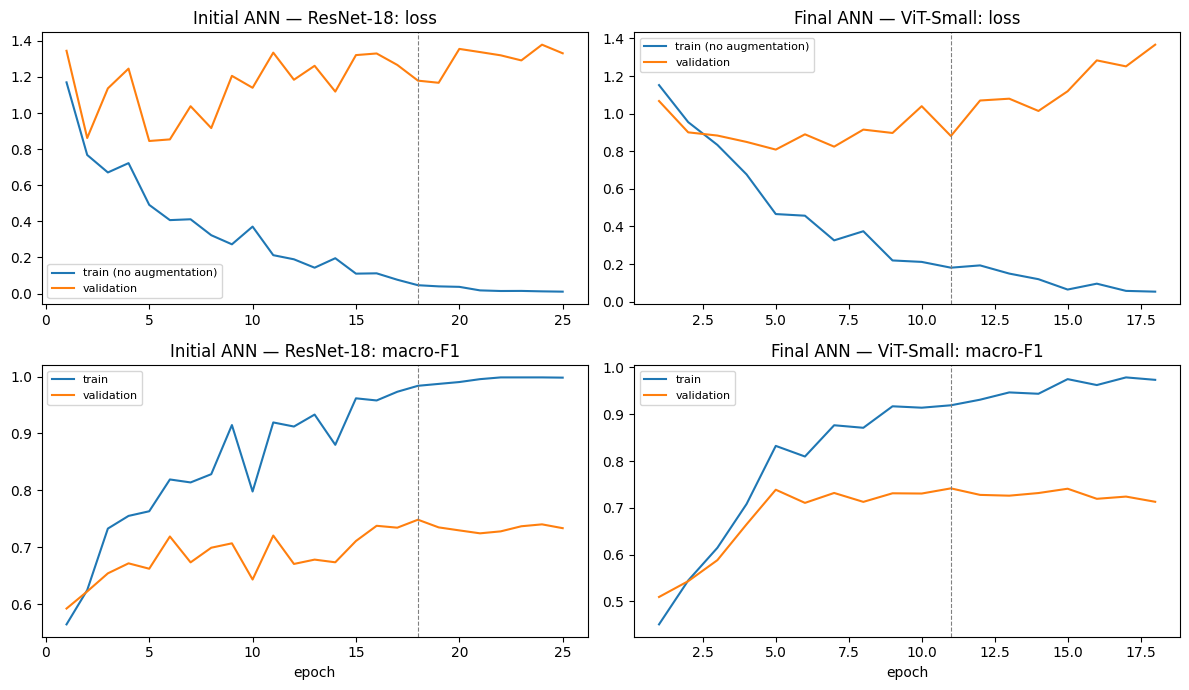

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, (name, rid) in enumerate([("Initial ANN — ResNet-18", "S3-R18-INIT-s42"), ("Final ANN — ViT-Small", "S3-VIT-FINAL-s42")]):
    h = pd.read_csv(RUNS / rid / "history.csv")
    best_ep = json.load(open(RUNS / rid / "result.json")).get("best_epoch")
    axes[0, col].plot(h.epoch, h.train_loss, label="train (no augmentation)"); axes[0, col].plot(h.epoch, h.val_loss, label="validation")
    axes[1, col].plot(h.epoch, h.train_macro_f1, label="train"); axes[1, col].plot(h.epoch, h.val_macro_f1, label="validation")
    for r in (0, 1):
        axes[r, col].axvline(best_ep, ls="--", c="grey", lw=0.8); axes[r, col].legend(fontsize=8)
    axes[0, col].set_title(f"{name}: loss"); axes[1, col].set_title(f"{name}: macro-F1"); axes[1, col].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT3 / "learning_curves.png", dpi=150); plt.show()

### 6.3 Optimisation-study plots (ViT, validation macro-F1)

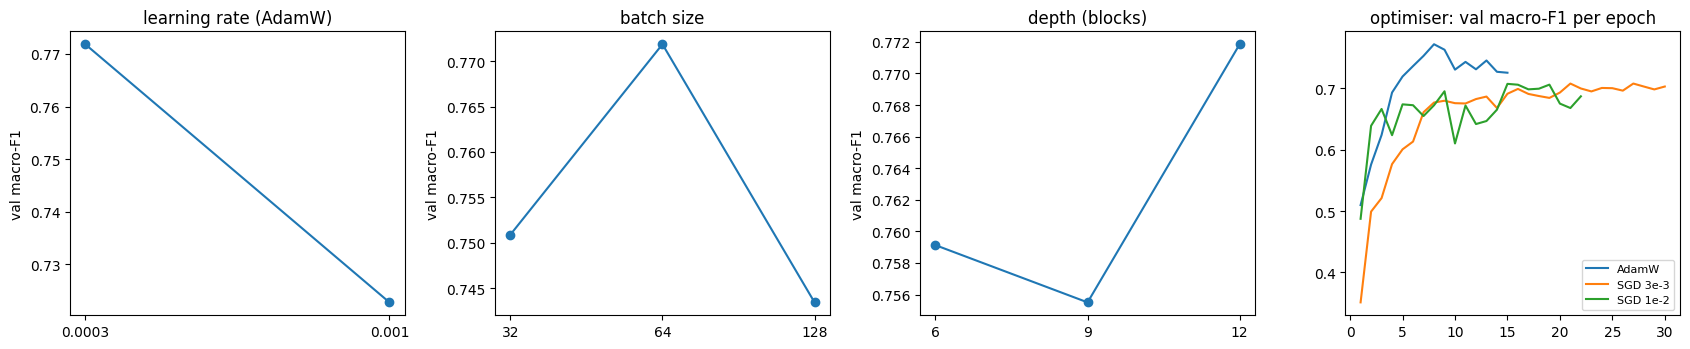

In [ ]:
t = results_table("S3-VIT")
lr_runs = t[(t.opt == "adamw") & (t.bs == bv["bs"]) & (t.depth == bv["depth"]) & (t.n_frozen == bv["n_frozen"]) &
            (t.class_weights) & (t.view == "full") & (t.wd == bv["wd"]) & (t.scenes == bv["scenes"]) & (t.seed == SEED)]
panels = {"learning rate (AdamW)": lr_runs.groupby("lr").val_macro_f1.max(),
          "batch size": t[t.run_id.isin([bv["run_id"], "S3-VIT-S-BS32", "S3-VIT-S-BS128"])].set_index("bs").val_macro_f1.sort_index(),
          "depth (blocks)": t[t.run_id.isin([bv["run_id"], "S3-VIT-S-D6", "S3-VIT-S-D9"])].set_index("depth").val_macro_f1.sort_index()}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, (title, s) in zip(axes, panels.items()):
    ax.plot(s.index.astype(str), s.values, marker="o"); ax.set_title(title); ax.set_ylabel("val macro-F1")
for rid, lab in [(bv["run_id"], "AdamW"), ("S3-VIT-S-SGD3e-3", "SGD 3e-3"), ("S3-VIT-S-SGD1e-2", "SGD 1e-2")]:
    if (RUNS / rid / "history.csv").exists():
        h = pd.read_csv(RUNS / rid / "history.csv"); axes[3].plot(h.epoch, h.val_macro_f1, label=lab)
axes[3].set_title("optimiser: val macro-F1 per epoch"); axes[3].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT3 / "optimisation_study.png", dpi=150); plt.show()

### 6.4 Confusion matrix of the final ViT (validation, seed 42)

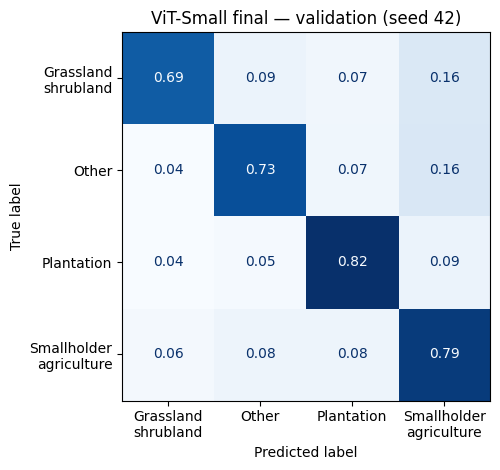

In [ ]:
vp = np.load(RUNS / "S3-VIT-FINAL-s42" / "val_pred.npy")
cm = confusion_matrix(man.y.values[VA_IDX], vp, labels=range(len(CLASSES)), normalize="true")
ConfusionMatrixDisplay(cm, display_labels=[c.replace(" ", "\n") for c in CLASSES]).plot(cmap="Blues", values_format=".2f", colorbar=False)
plt.title("ViT-Small final — validation (seed 42)"); plt.tight_layout(); plt.savefig(OUT3 / "confusion_vit_final.png", dpi=150); plt.show()

### 6.5 Inference latency (end-to-end, one image)
Measured from **reading the PNG from local disk** → resize → normalise → model → prediction, one image at a time,
median of 50 validation images (first 5 ignored as warm-up). Reported on GPU and on CPU (the web app may run on CPU).

In [ ]:
def latency_ms(model, view, device, n=50):
    raw = ensure_raw(); model = model.to(device).eval()
    mean, std = MEAN.to(device), STD.to(device); times = []
    for p in man.example_path.values[VA_IDX][:n]:
        t0 = time.perf_counter()
        im = load_view(Image.open(raw / p / "images" / "visible" / "composite.png").convert("RGB"), view)
        x = (torch.from_numpy(im).permute(2, 0, 1)[None].float().to(device) / 255.0 - mean) / std
        with torch.no_grad():
            model(x).argmax(1)
        if device == "cuda":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times[5:]))

lat = {}
for name, rid in [("ResNet-18 (initial)", "S3-R18-INIT-s42"), ("ResNet-18 (tuned)", "S3-R18-FINAL-s42"),
                  ("EfficientNet-B2", "S3-EFB2-FINAL-s42"), ("ViT-Small (final)", "S3-VIT-FINAL-s42")]:
    c = json.load(open(RUNS / rid / "result.json"))["cfg"]
    m = build_model(c); m.load_state_dict(torch.load(RUNS / rid / "best.pt", map_location="cpu"))
    tot, _ = count_params(m)
    lat[name] = {"params_M": round(tot / 1e6, 2),
                 "gpu_ms": round(latency_ms(m, c["view"], "cuda"), 2) if DEV == "cuda" else None,
                 "cpu_ms": round(latency_ms(m, c["view"], "cpu"), 2)}
lat_df = pd.DataFrame(lat).T; display(lat_df); lat_df.to_csv(OUT3 / "latency.csv")

,params_M,gpu_ms,cpu_ms
ResNet-18 (initial),11.18,13.52,89.36
ResNet-18 (tuned),11.18,15.54,66.5
EfficientNet-B2,7.71,18.29,63.89
ViT-Small (final),21.87,19.3,120.8


## 7. Summary

In [ ]:
print("=== STAGE 3 SUMMARY ===")
allr = results_table("S3-")
print("Runs:", len(allr), "| failed:", int((allr.outcome != "ok").sum()),
      "| total GPU time (min):", round(allr.train_min.sum(), 1))
for a, c in FINAL_CFG.items():
    print(a, "final config:", c["run_id"], {k: c[k] for k in ("lr", "wd", "bs", "opt", "scenes", "view", "depth", "n_frozen")})
display(val_table); display(lat_df)
display(allr.sort_values("val_macro_f1", ascending=False))

=== STAGE 3 SUMMARY ===
Runs: 47 | failed: 0 | total GPU time (min): 101.8
resnet18 final config: S3-R18-T03 {'lr': 0.0003, 'wd': 0.01, 'bs': 64, 'opt': 'adamw', 'scenes': 'none', 'view': 'full', 'depth': 12, 'n_frozen': 3}
effnet_b2 final config: S3-EFB2-T05 {'lr': 0.001, 'wd': 0.01, 'bs': 64, 'opt': 'adamw', 'scenes': 'none', 'view': 'full', 'depth': 12, 'n_frozen': 3}
vit_small final config: S3-VIT-T06 {'lr': 0.0003, 'wd': 0.01, 'bs': 64, 'opt': 'adamw', 'scenes': 'clear', 'view': 'full', 'depth': 12, 'n_frozen': 3}


,macro_f1,accuracy,recall_plantation,recall_smallholder,recall_other,recall_grassland,rate_P_to_S,rate_O_to_SG,train_min
ResNet-18 (initial ANN),0.732 ± 0.025,0.782 ± 0.020,0.876 ± 0.032,0.733 ± 0.069,0.738 ± 0.033,0.541 ± 0.026,0.086 ± 0.034,0.219 ± 0.022,0.898 ± 0.366
ResNet-18 (tuned),0.737 ± 0.037,0.784 ± 0.030,0.865 ± 0.034,0.774 ± 0.053,0.724 ± 0.030,0.519 ± 0.071,0.093 ± 0.032,0.214 ± 0.029,0.953 ± 0.490
EfficientNet-B2 (tuned),0.758 ± 0.013,0.808 ± 0.013,0.869 ± 0.017,0.826 ± 0.021,0.729 ± 0.000,0.578 ± 0.059,0.089 ± 0.016,0.200 ± 0.014,3.982 ± 0.233
ViT-Small (final ANN),0.760 ± 0.017,0.802 ± 0.016,0.855 ± 0.031,0.833 ± 0.041,0.681 ± 0.044,0.637 ± 0.046,0.098 ± 0.010,0.248 ± 0.044,2.155 ± 0.580


,params_M,gpu_ms,cpu_ms
ResNet-18 (initial),11.18,13.52,89.36
ResNet-18 (tuned),11.18,15.54,66.5
EfficientNet-B2,7.71,18.29,63.89
ViT-Small (final),21.87,19.3,120.8


,run_id,arch,lr,wd,bs,opt,scenes,view,depth,n_frozen,class_weights,seed,val_macro_f1,best_epoch,train_min,outcome
11,S3-R18-FINAL-s42,resnet18,0.0003,0.01,64,adamw,none,full,12,3,True,42,0.7766,24,1.459,ok
19,S3-R18-T03,resnet18,0.0003,0.01,64,adamw,none,full,12,3,True,42,0.7766,24,1.454,ok
27,S3-VIT-FINAL-s43,vit_small,0.0003,0.01,64,adamw,clear,full,12,3,True,43,0.7747,17,2.769,ok
43,S3-VIT-T06,vit_small,0.0003,0.01,64,adamw,clear,full,12,3,True,42,0.7719,8,1.733,ok
2,S3-EFB2-FINAL-s44,effnet_b2,0.001,0.01,64,adamw,none,full,12,3,True,44,0.7709,20,3.713,ok
39,S3-VIT-T02,vit_small,3e-05,0.05,64,adamw,clear,full,12,3,True,42,0.7648,22,3.342,ok
28,S3-VIT-FINAL-s44,vit_small,0.0003,0.01,64,adamw,clear,full,12,3,True,44,0.7647,7,1.618,ok
40,S3-VIT-T03,vit_small,0.0001,0.01,64,adamw,none,full,12,3,True,42,0.7634,22,3.346,ok
38,S3-VIT-T01,vit_small,3e-05,0.01,64,adamw,none,full,12,3,True,42,0.7607,11,2.124,ok
33,S3-VIT-S-FRZ0,vit_small,0.0003,0.01,64,adamw,clear,full,12,0,True,42,0.7597,7,1.842,ok


In [ ]:
# Phase 3b — complete the learning-rate curve and repeat key study runs with 3 seeds
P3b = [study("S3-VIT-S-LR3e-5", "study: learning rate 3e-5", lr=3e-5),
       study("S3-VIT-S-LR1e-4", "study: learning rate 1e-4", lr=1e-4)]
for s in (43, 44):
    P3b += [study(f"S3-VIT-S-LR1e-3-s{s}", f"study: learning rate 1e-3, seed {s}", lr=1e-3, seed=s),
            study(f"S3-VIT-S-SGD3e-3-s{s}", f"study: SGD momentum lr 3e-3, seed {s}", opt="sgd", lr=3e-3, seed=s),
            study(f"S3-VIT-S-D6-s{s}", f"study: depth 6 blocks, seed {s}", depth=6, seed=s)]
run_all(P3b)

def grp(ids):
    v = [json.load(open(RUNS / i / "result.json"))["val"]["macro_f1"] for i in ids if (RUNS / i / "result.json").exists()]
    return f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f} (n={len(v)})"
display(pd.Series({
    "AdamW lr 3e-4, 12 blocks (final config)": grp([f"S3-VIT-FINAL-s{s}" for s in (42, 43, 44)]),
    "AdamW lr 1e-3": grp(["S3-VIT-S-LR1e-3", "S3-VIT-S-LR1e-3-s43", "S3-VIT-S-LR1e-3-s44"]),
    "SGD momentum lr 3e-3": grp(["S3-VIT-S-SGD3e-3", "S3-VIT-S-SGD3e-3-s43", "S3-VIT-S-SGD3e-3-s44"]),
    "Depth 6 blocks": grp(["S3-VIT-S-D6", "S3-VIT-S-D6-s43", "S3-VIT-S-D6-s44"]),
}, name="val macro-F1 (mean ± sd)"))

S3-VIT-S-LR3e-5: val macro-F1 0.7641 | best epoch 22/29 | 3.3 min
S3-VIT-S-LR1e-4: val macro-F1 0.7247 | best epoch 7/14 | 1.6 min
S3-VIT-S-LR1e-3-s43: val macro-F1 0.7445 | best epoch 18/25 | 2.8 min
S3-VIT-S-SGD3e-3-s43: val macro-F1 0.7188 | best epoch 12/19 | 2.2 min
S3-VIT-S-D6-s43: val macro-F1 0.7513 | best epoch 19/26 | 1.4 min
S3-VIT-S-LR1e-3-s44: val macro-F1 0.7271 | best epoch 6/13 | 1.5 min
S3-VIT-S-SGD3e-3-s44: val macro-F1 0.7153 | best epoch 16/23 | 2.7 min
S3-VIT-S-D6-s44: val macro-F1 0.7323 | best epoch 7/14 | 0.7 min


,val macro-F1 (mean ± sd)
"AdamW lr 3e-4, 12 blocks (final config)",0.760 ± 0.017 (n=3)
AdamW lr 1e-3,0.731 ± 0.012 (n=3)
SGD momentum lr 3e-3,0.714 ± 0.006 (n=3)
Depth 6 blocks,0.748 ± 0.014 (n=3)
